<a href="https://colab.research.google.com/github/kimve1969/PINN/blob/main/basis_functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Полиномы Лежандра и Чебышёва



ПОЛИНОМЫ ЛЕЖАНДРА P_n(x), n = 0..4
P_0(x) = 1
P_1(x) = 1·x
P_2(x) = -0.5 + 1.5·x^2
P_3(x) = -1.5·x + 2.5·x^3
P_4(x) = 0.375 - 3.75·x^2 + 4.375·x^4

ПОЛИНОМЫ ЧЕБЫШЁВА T_n(x), n = 0..4
T_0(x) = 1
T_1(x) = 1·x
T_2(x) = -1 + 2·x^2
T_3(x) = -3·x + 4·x^3
T_4(x) = 1 - 8·x^2 + 8·x^4


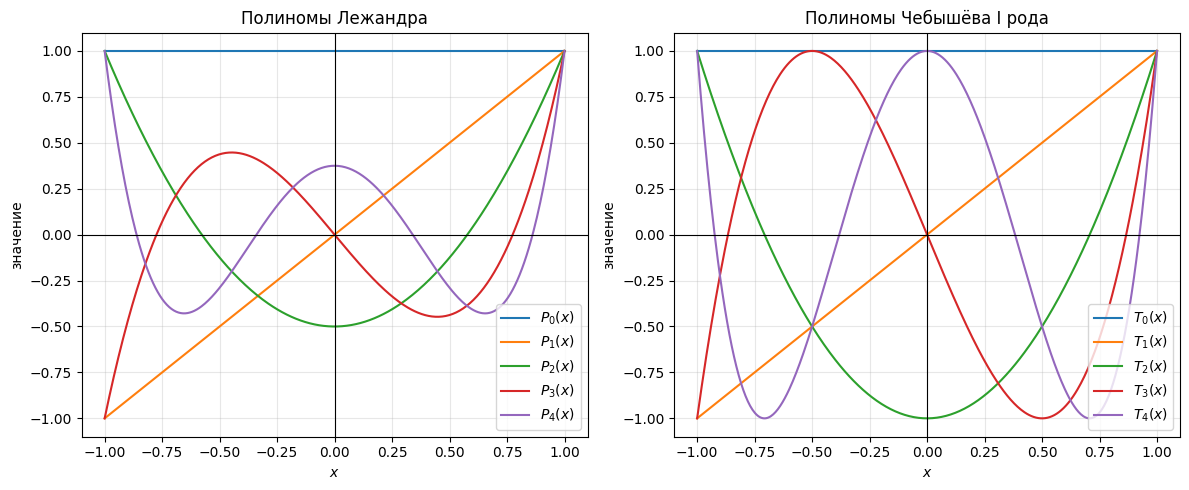

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import legendre, chebyt

def poly_str(coeffs):
    """Строка вида c0 + c1·x + c2·x^2 + ..."""
    terms = []
    for deg, c in enumerate(reversed(coeffs)):
        if abs(c) < 1e-12:
            continue
        if deg == 0:
            terms.append(f"{c:g}")
        elif deg == 1:
            terms.append(f"{c:g}·x")
        else:
            terms.append(f"{c:g}·x^{deg}")
    return " + ".join(terms).replace("+ -", "- ") if terms else "0"

# ---------- Вывод полиномов ----------
print("=" * 60)
print("ПОЛИНОМЫ ЛЕЖАНДРА P_n(x), n = 0..4")
print("=" * 60)
for n in range(5):
    print(f"P_{n}(x) = {poly_str(legendre(n).coefficients)}")

print()
print("=" * 60)
print("ПОЛИНОМЫ ЧЕБЫШЁВА T_n(x), n = 0..4")
print("=" * 60)
for n in range(5):
    print(f"T_{n}(x) = {poly_str(chebyt(n).coefficients)}")

# ---------- Графики ----------
x = np.linspace(-1, 1, 400)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for n in range(5):
    ax[0].plot(x, legendre(n)(x), label=f"$P_{n}(x)$")
    ax[1].plot(x, chebyt(n)(x), label=f"$T_{n}(x)$")

titles = ["Полиномы Лежандра", "Полиномы Чебышёва I рода"]
for a, title in zip(ax, titles):
    a.set_title(title)
    a.set_xlabel("$x$")
    a.set_ylabel("значение")
    a.grid(alpha=0.3)
    a.axhline(0, color="black", linewidth=0.8)
    a.axvline(0, color="black", linewidth=0.8)
    a.legend()

plt.tight_layout()
plt.show()

In [18]:
from scipy.special import legendre, chebyt
legendre(3).coefficients

array([ 2.5,  0. , -1.5,  0. ])

In [15]:
P = legendre(3)
P

poly1d([ 2.5,  0. , -1.5,  0. ])

In [19]:
P(2.2)

np.float64(23.320000000000007)

In [21]:
def myP(x):
  return 2.5*x**3 + 0*x**2 - 1.5*x**1 + 0*x**0
myP(2.2)

23.320000000000007

Аппроксимация одиночного импульса полиномами Лежандра

Теория (кратко)

Одиночный импульс на $[-1, 1]$:

f(t) = \begin{cases} 1, & |t| \le 0.2 \\ 0, & \text{иначе} \end{cases}

Разложение по ортогональному базису Лежандра:

$$
f(t) \approx \sum_{n=0}^{N-1} c_n P_n(t), \qquad c_n = \frac{2n+1}{2} \int_{-1}^{1} f(t)\,P_n(t)\,dt
$$

Интеграл считаем численно (scipy.integrate.quad)

Коэффициенты c_n:
c_0 =  0.200000
c_1 =  0.000000
c_2 = -0.480000
c_3 =  0.000000
c_4 =  0.587520
c_5 =  0.000000
c_6 = -0.601037
c_7 = -0.000000
c_8 =  0.539474
c_9 =  0.000000
c_10 = -0.420272
c_11 = -0.000000
c_12 =  0.264015
c_13 =  0.000000
c_14 = -0.093569
c_15 = -0.000000
c_16 = -0.068236
c_17 =  0.000000
c_18 =  0.201260
c_19 = -0.000000
c_20 = -0.290443
c_21 =  0.000000
c_22 =  0.327512
c_23 = -0.000000
c_24 = -0.311751
c_25 =  0.000000
c_26 =  0.249720
c_27 = -0.000000
c_28 = -0.153999
c_29 =  0.000000
c_30 =  0.041137
c_31 = -0.000000
c_32 =  0.070875
c_33 =  0.000000
c_34 = -0.165233
c_35 =  0.000000
c_36 =  0.228679
c_37 = -0.000000
c_38 = -0.253258
c_39 =  0.000000
c_40 =  0.237230
c_41 = -0.000000
c_42 = -0.185048
c_43 =  0.000000
c_44 =  0.106424
c_45 = -0.000000
c_46 = -0.014651
c_47 =  0.000000
c_48 = -0.075543
c_49 = -0.000000


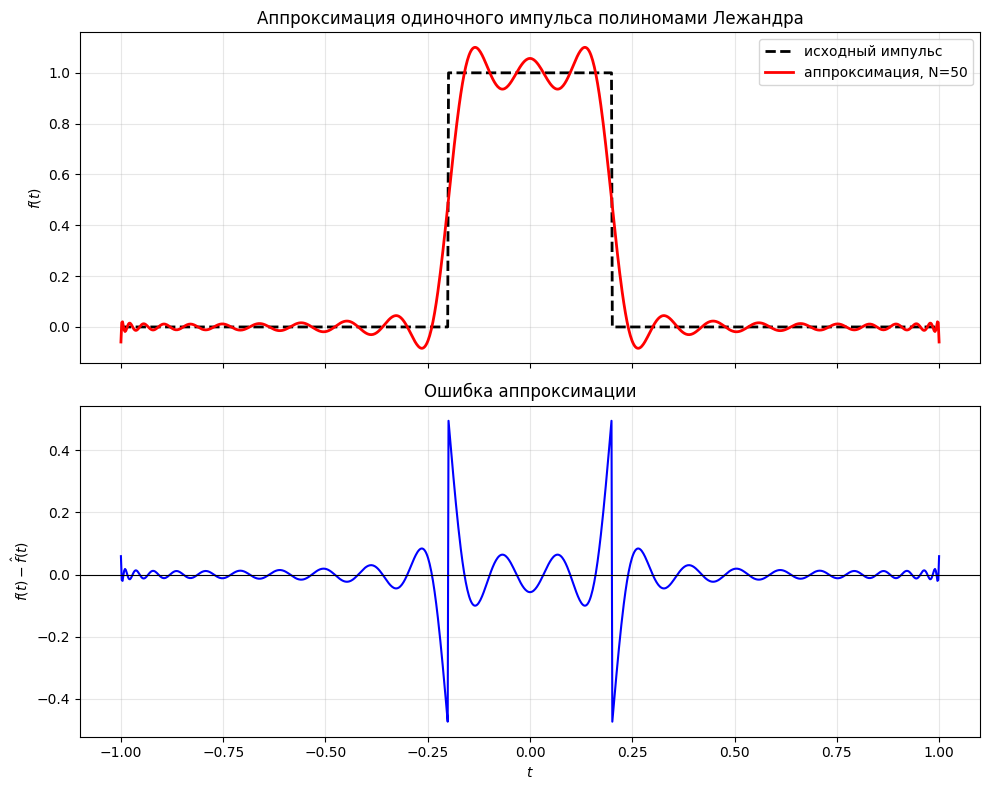


RMSE = 0.08104
max |error| = 0.49537


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import legendre
from scipy.integrate import quad

# ---------- Исходный сигнал: одиночный прямоугольный импульс ----------
def pulse(t, width=0.2):
    return np.where(np.abs(t) <= width, 1.0, 0.0)

# ---------- Коэффициенты разложения ----------
N = 50                      # число базисных функций
coeffs = np.zeros(N)

for n in range(N):
    Pn = legendre(n)
    integrand = lambda t, Pn=Pn: pulse(t) * Pn(t)
    val, _ = quad(integrand, -1, 1, limit=200)
    coeffs[n] = (2 * n + 1) / 2 * val

print("Коэффициенты c_n:")
for n, c in enumerate(coeffs):
    print(f"c_{n} = {c: .6f}")

# ---------- Аппроксимация ----------
t = np.linspace(-1, 1, 1000)
f_true = pulse(t)

f_approx = np.zeros_like(t)
for n in range(N):
    f_approx += coeffs[n] * legendre(n)(t)

error = f_true - f_approx

# ---------- Графики ----------
fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# 1) Сигнал и аппроксимация
ax[0].plot(t, f_true, 'k--', linewidth=2, label='исходный импульс')
ax[0].plot(t, f_approx, 'r-', linewidth=2,
           label=f'аппроксимация, N={N}')
ax[0].set_ylabel('$f(t)$')
ax[0].set_title('Аппроксимация одиночного импульса полиномами Лежандра')
ax[0].grid(alpha=0.3)
ax[0].legend()

# 2) Ошибка
ax[1].plot(t, error, 'b-', linewidth=1.5)
ax[1].axhline(0, color='black', linewidth=0.8)
ax[1].set_xlabel('$t$')
ax[1].set_ylabel('$f(t) - \\hat{f}(t)$')
ax[1].set_title('Ошибка аппроксимации')
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ---------- Метрики качества ----------
rmse = np.sqrt(np.mean(error**2))
max_err = np.max(np.abs(error))
print(f"\nRMSE = {rmse:.5f}")
print(f"max |error| = {max_err:.5f}")